# Overlap of DEGs
I'm interested if there are shared DEGs among oysters that experience stressors at different ages (or if the DEGs I identify are purely due to differences in the age of the oysters)

## 0. load libraries

In [ ]:
library(tidyverse)

# for venn diagrams/upset plots
library(ggvenn)
library(UpSetR)

# for visualization
library(virdis)
library(RColorBrewer)

## 1. read csvs

### all genes
from [DESeq](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/compare_phases/deseq_comparePhase.ipynb)

for all of these, the "baseline" is the phase 1 oyster 

In [6]:
# CONTROL
cc_c <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cc_c.csv') %>%
rename('Gene' = X)

# HYPOXIC
ch_h <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/ch_h.csv') %>%
rename('Gene' = X)

# WARM
cw_w <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cw_w.csv') %>%
rename('Gene' = X)

cb_b <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cb_b.csv') %>%
rename('Gene' = X)
head(cb_b)

,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,2085.5663,-0.04563055,0.1833458,0.748297600,0.91452790
2,LOC144621269,2556.3795,-0.06500174,0.3789901,0.440654021,0.74859859
3,LOC111120925,142.0638,0.91139689,1.5574705,0.002487047,0.04746309
4,LOC144621283,888.4466,0.15319682,0.1830420,0.281962171,0.62166646
5,LOC144621276,12535.4692,0.41424753,0.1807497,0.003627159,0.05943955
6,LOC111115920,180.4656,-0.26129043,0.2759291,0.080019987,0.33005602


In [9]:
df_list <- list(control = cc_c, 
                warm = cw_w, 
                hypoxic = ch_h, 
                both = cb_b)
names(df_list)

[1] "control" "warm"    "hypoxic" "both"

### DEGs

In [11]:
deg.list <- lapply(df_list, function(df) filter(df, padj < 0.05 & abs(log2FoldChange > 1)))

## 2. venn diagram

Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


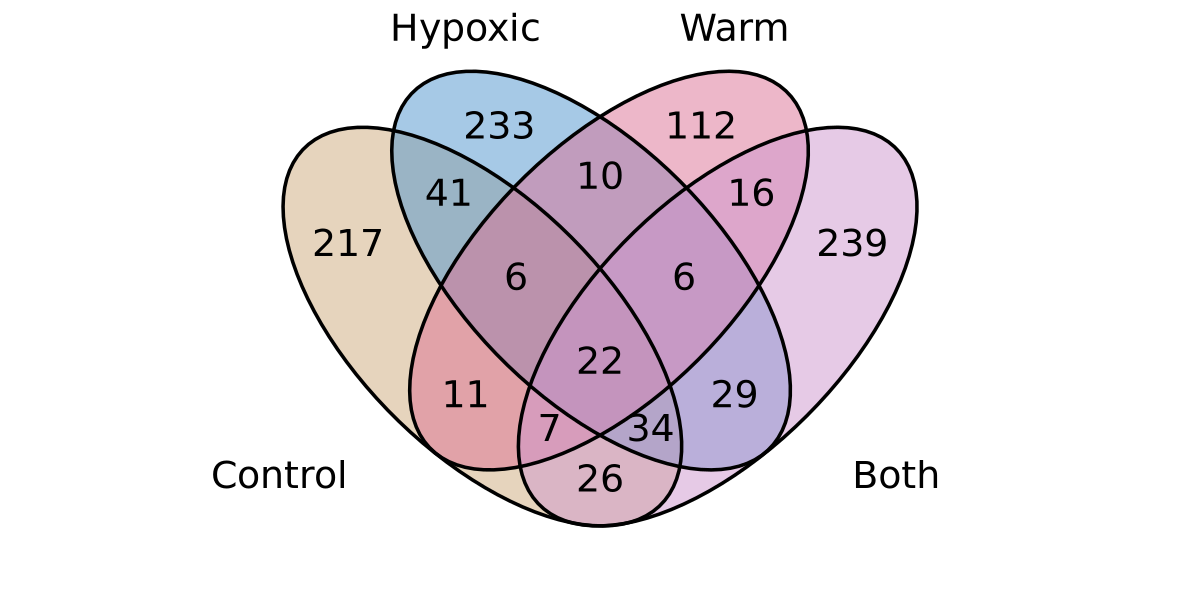

In [14]:
options(repr.plot.width=10, repr.plot.height=5)

# make list of dfs
x = list('Control' = deg.list$control$Gene,
         'Hypoxic' = deg.list$hypoxic$Gene,
        'Warm' = deg.list$warm$Gene,
        'Both' = deg.list$both$Gene)

ggvenn(x,
       fill_color = c("burlywood3", "steelblue3", "palevioletred", "plum3"),
       text_size = 8,
       set_name_size = 8,
       show_percentage = FALSE
) +
  coord_fixed(clip = "off") +
  theme(plot.margin = margin(t = 10, r = 10, b = 30, l = 10, unit = "pt"))

all DEGs are due to oysters experiencing the same treatment/stressor one time but at different timepoints (phase 1 or phase 2)

I think any DEG that overlaps with those from C vs. CC are safe to say that they're due to the age of the oyster - so I think I should remove those, and then look at the overlap of hypoxic, warm, and both to see if there's common differences between oysters (but similarities would only tell me that there might be a "general" response to stress that is shared across a phase (but you wouldn't know the direction just from this plot))